1-Import and use the existing loader

In [ ]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd().parents[1]))

from src.data.data_loader import load_dataset

df = load_dataset()

TARGET = "Mental_Health_Risk"


Dataset shape: (2000, 17)


3 — Target distribution

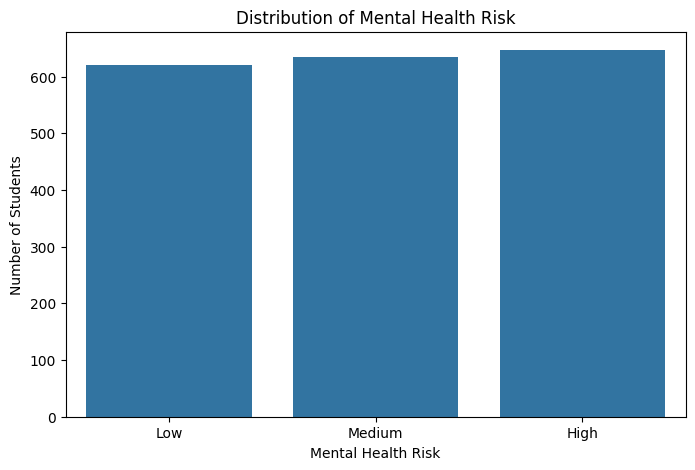

In [27]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=TARGET, order=["Low", "Medium", "High"])

plt.title("Distribution of Mental Health Risk")
plt.xlabel("Mental Health Risk")
plt.ylabel("Number of Students")

plt.show()

2. Numerical features distributions

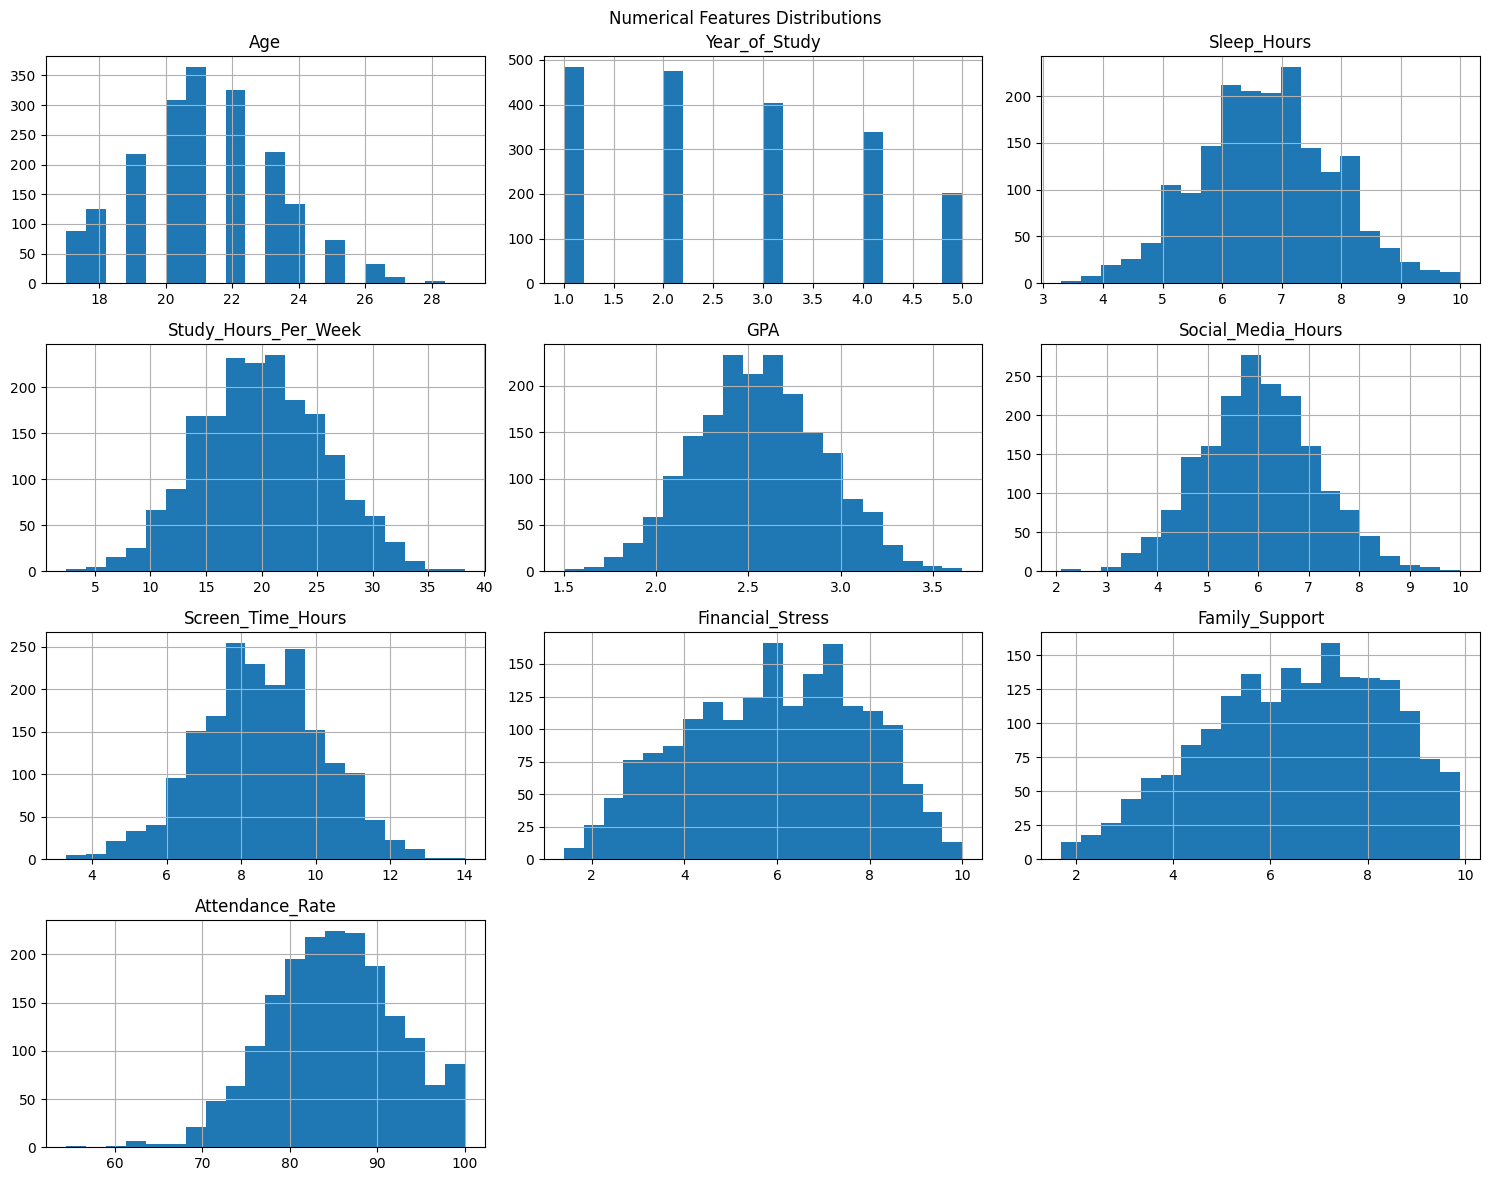

In [28]:

numerical_columns = df.select_dtypes(include="number").columns.drop("Student_ID", errors="ignore")

df[numerical_columns].hist(figsize=(15, 12), bins=20)

plt.suptitle("Numerical Features Distributions")
plt.tight_layout()
plt.show()

3. Categorical features distributions

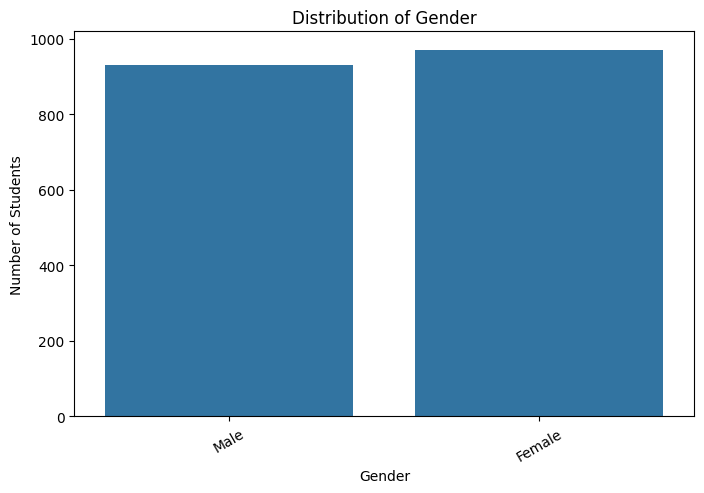

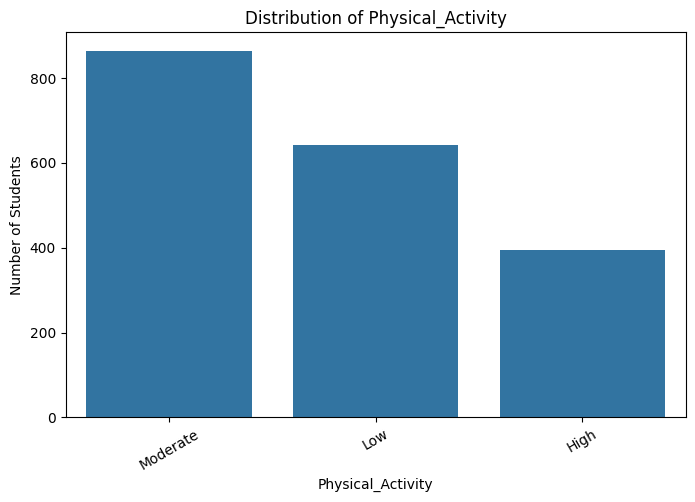

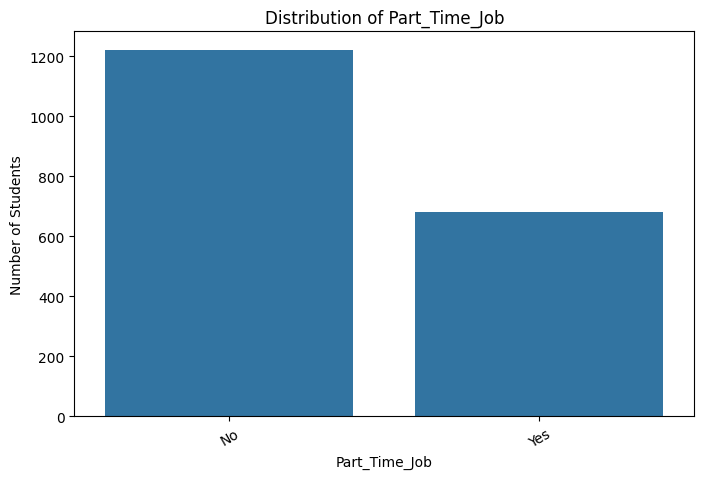

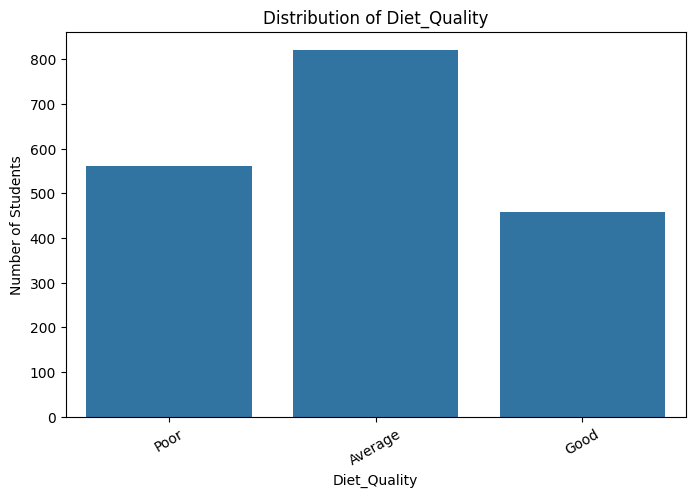

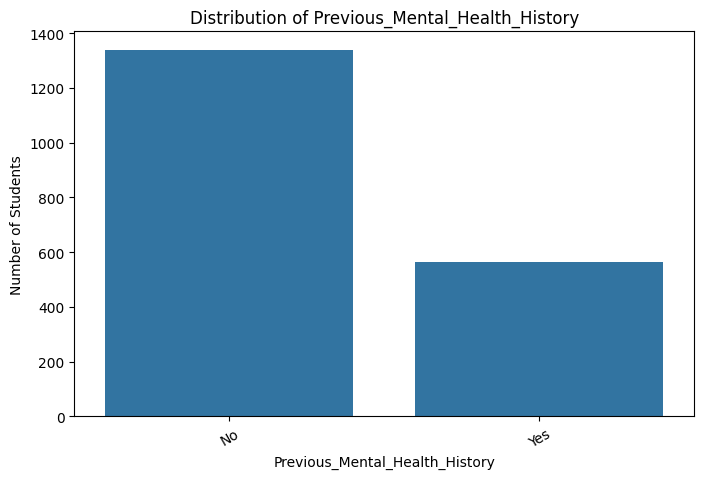

In [26]:

categorical_columns = df.select_dtypes(include="object").columns.drop(
    ["Student_ID", TARGET], errors="ignore"
)

for column in categorical_columns:
    plt.figure(figsize=(8, 5))

    sns.countplot(data=df, x=column)

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Students")
    plt.xticks(rotation=30)

    plt.show()

4. Numerical features outliers

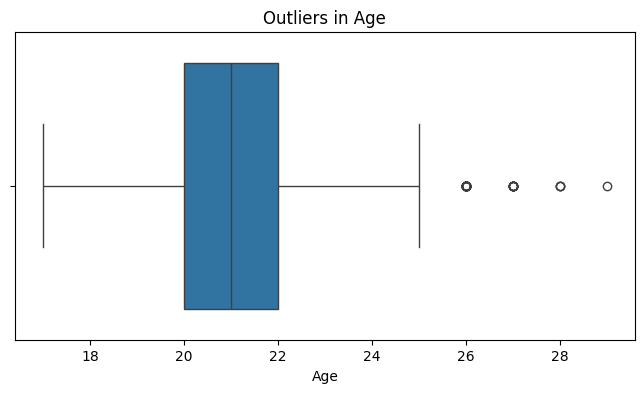

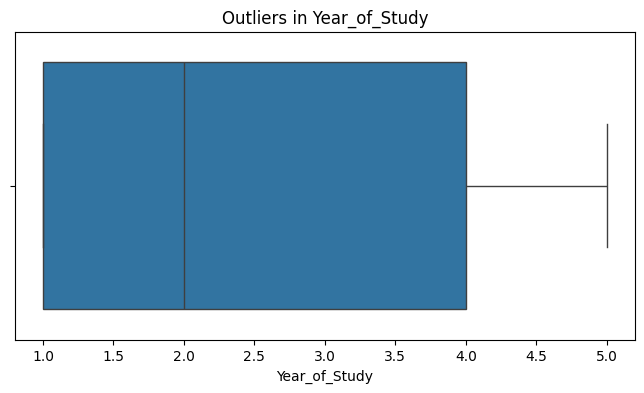

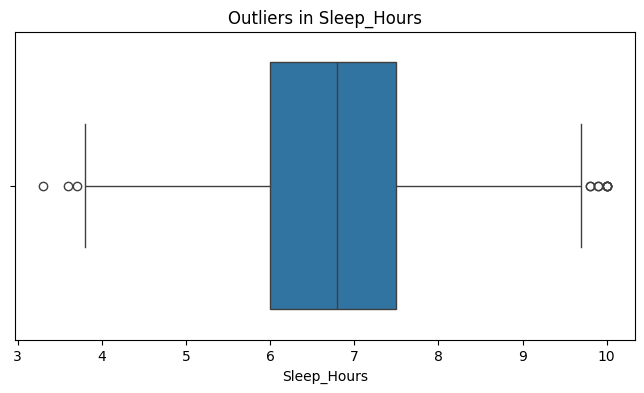

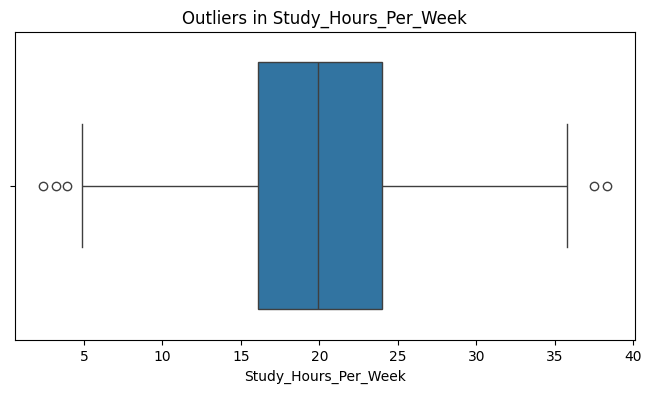

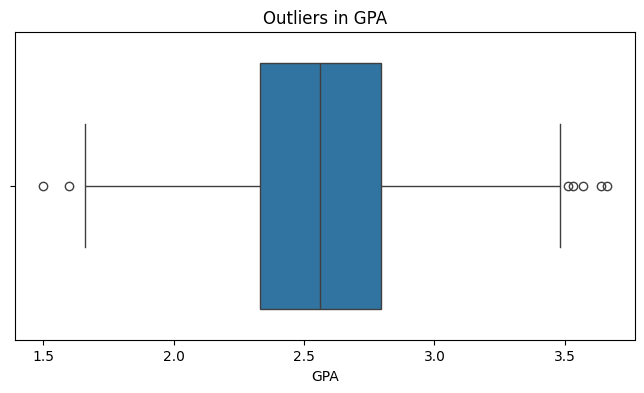

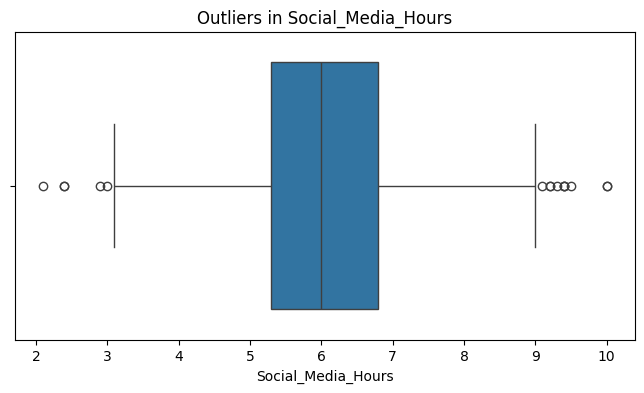

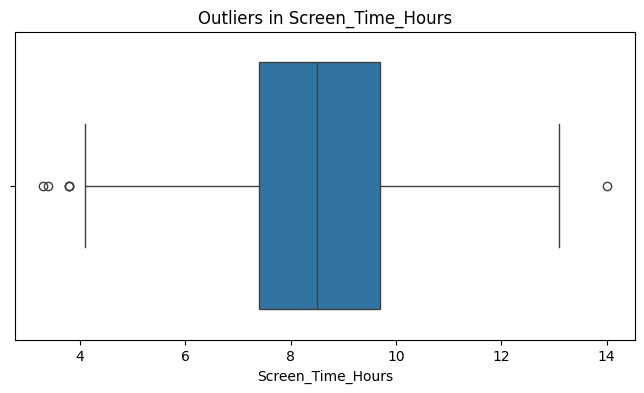

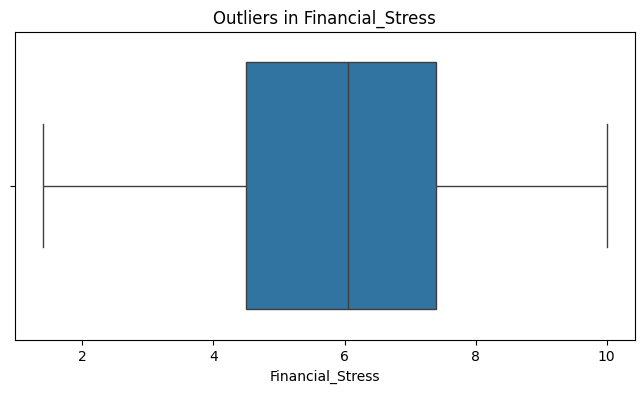

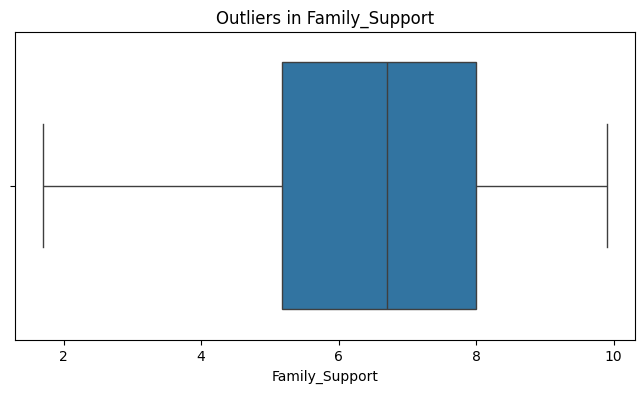

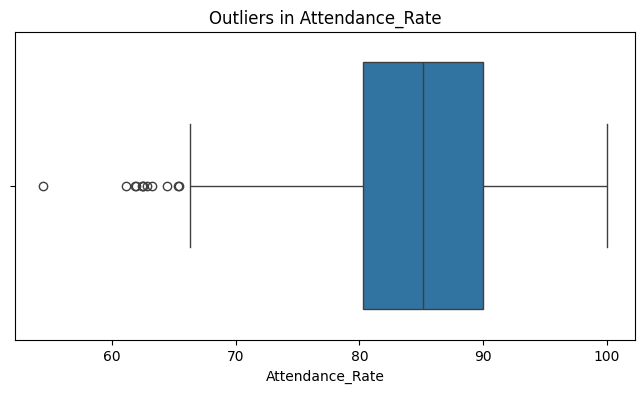

In [29]:

numerical_columns = df.select_dtypes(include="number").columns.drop("Student_ID", errors="ignore")

for column in numerical_columns:
    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df, x=column)

    plt.title(f"Outliers in {column}")
    plt.xlabel(column)

    plt.show()

5-Correlation heatmap

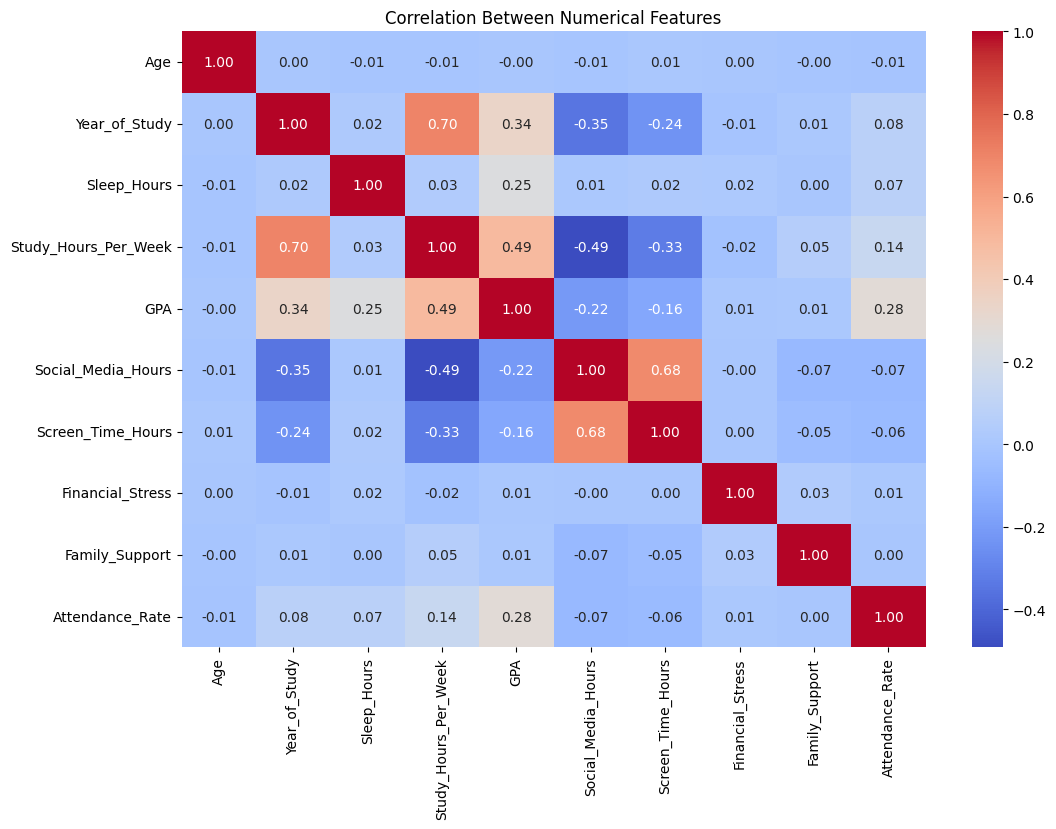

In [30]:

numerical_columns = df.select_dtypes(include="number").columns.drop("Student_ID", errors="ignore")

correlation = df[numerical_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Numerical Features")

plt.show()

6. Numerical features vs target

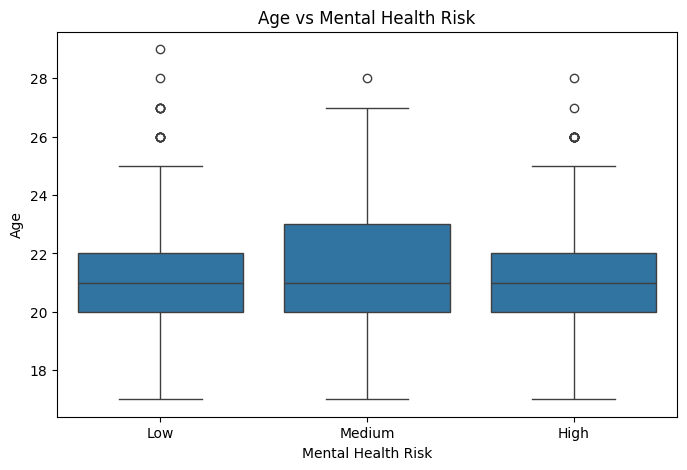

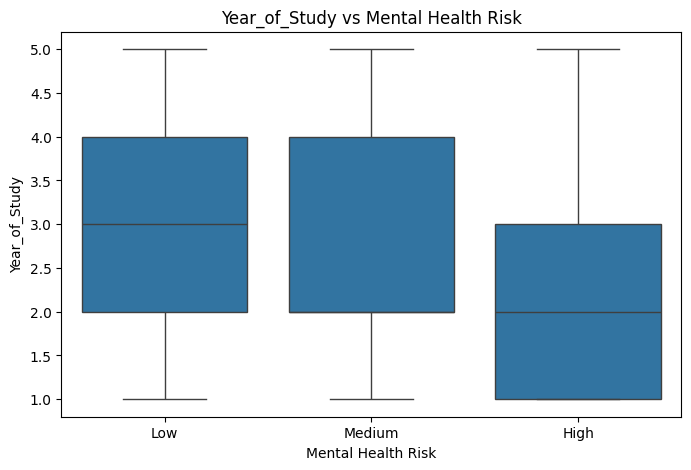

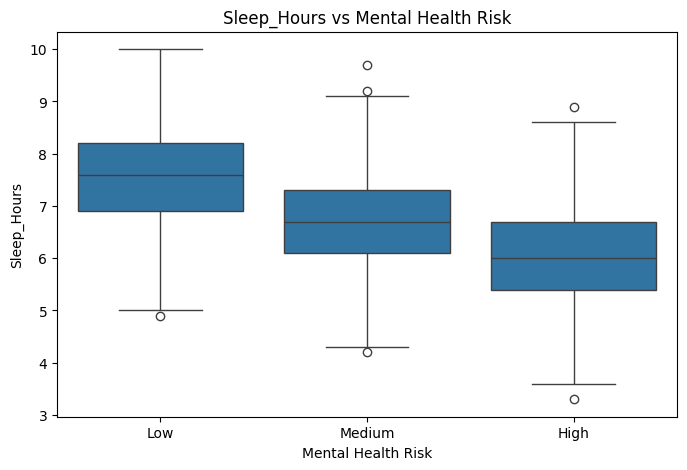

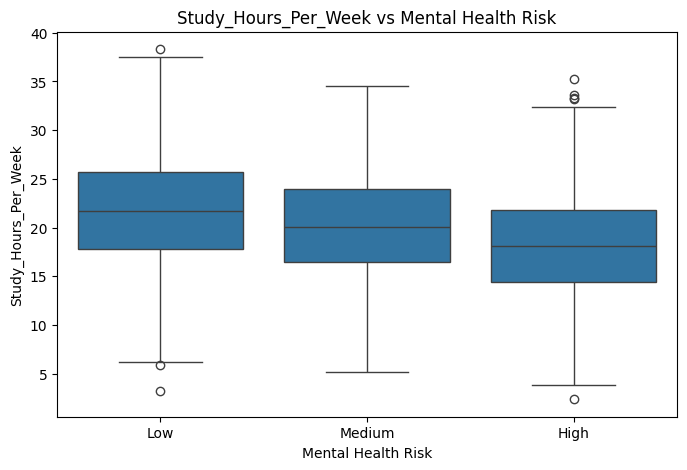

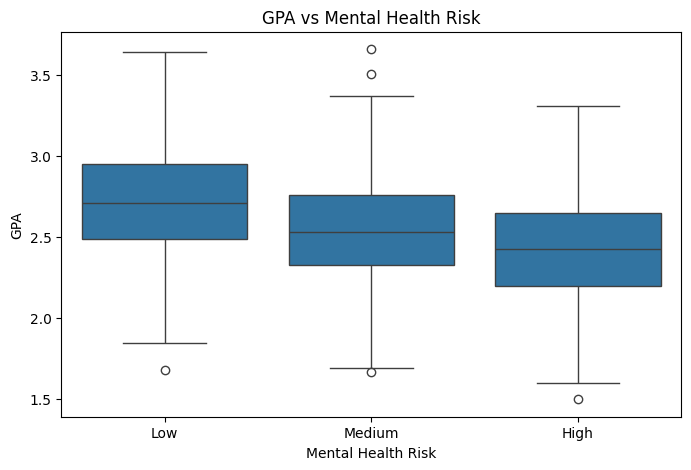

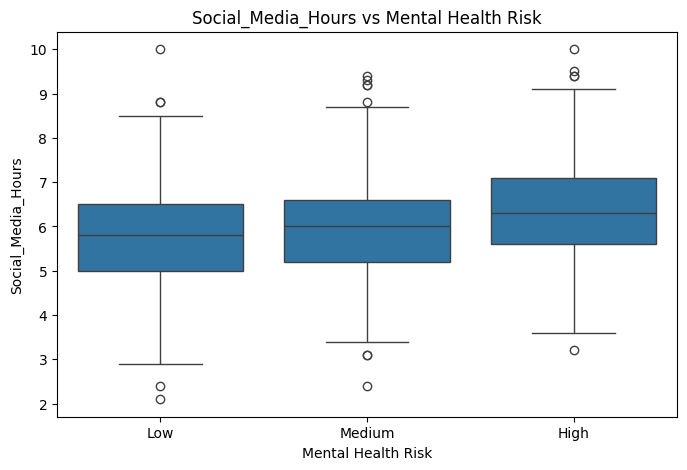

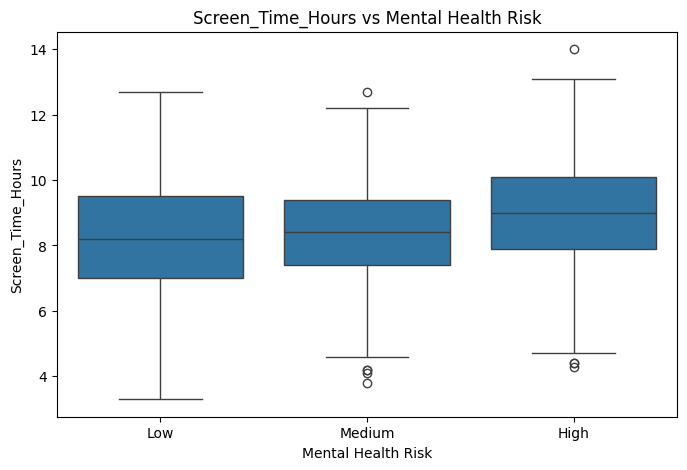

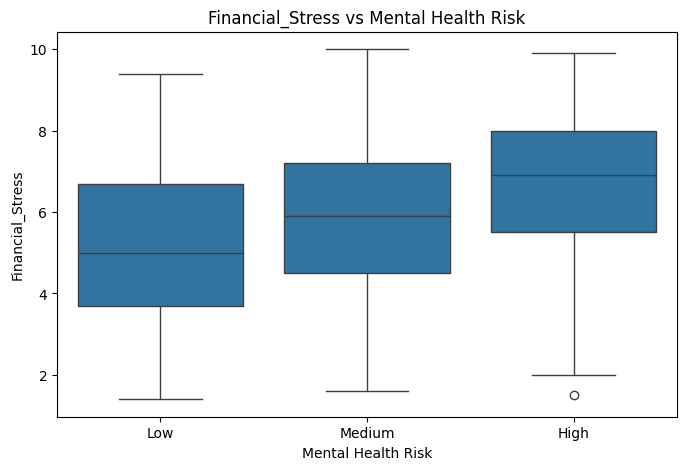

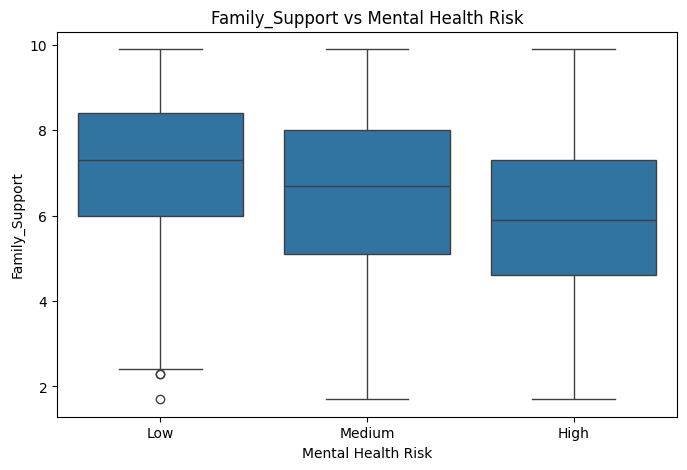

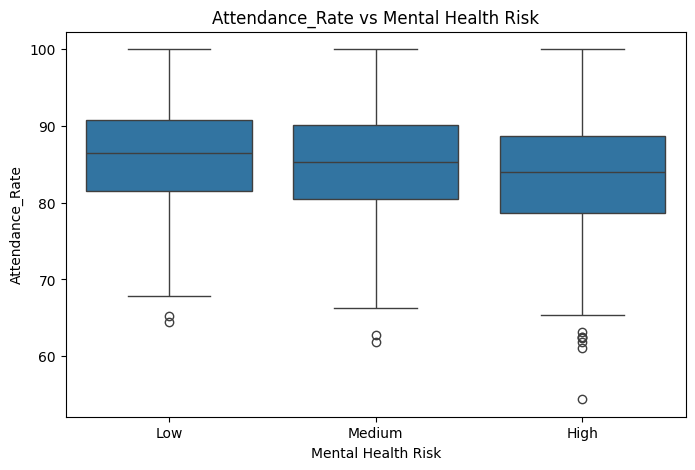

In [31]:

numerical_columns = df.select_dtypes(include="number").columns.drop("Student_ID", errors="ignore")

for column in numerical_columns:
    plt.figure(figsize=(8, 5))

    sns.boxplot(data=df, x=TARGET, y=column, order=["Low", "Medium", "High"])

    plt.title(f"{column} vs Mental Health Risk")
    plt.xlabel("Mental Health Risk")
    plt.ylabel(column)

    plt.show()

7. Categorical features vs target

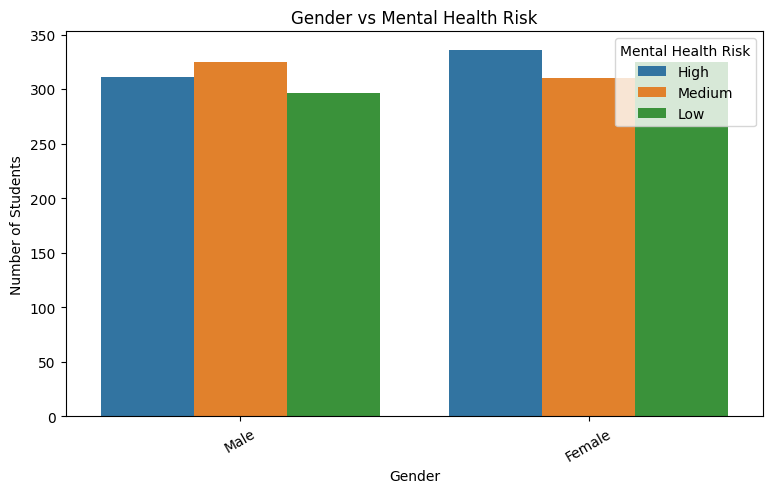

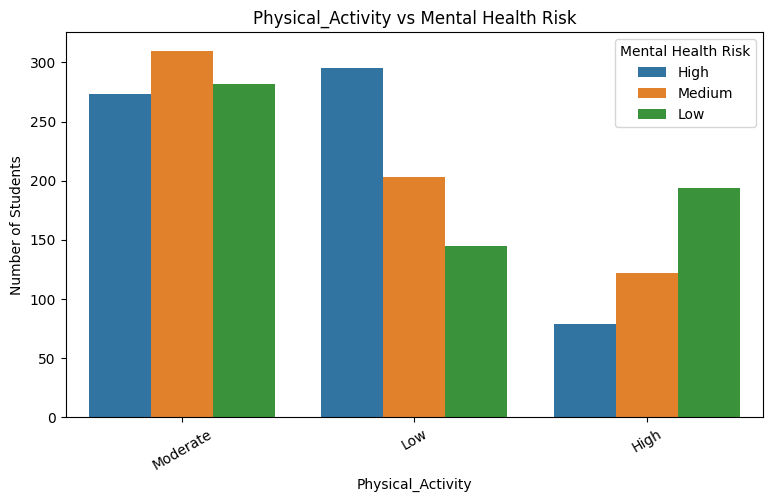

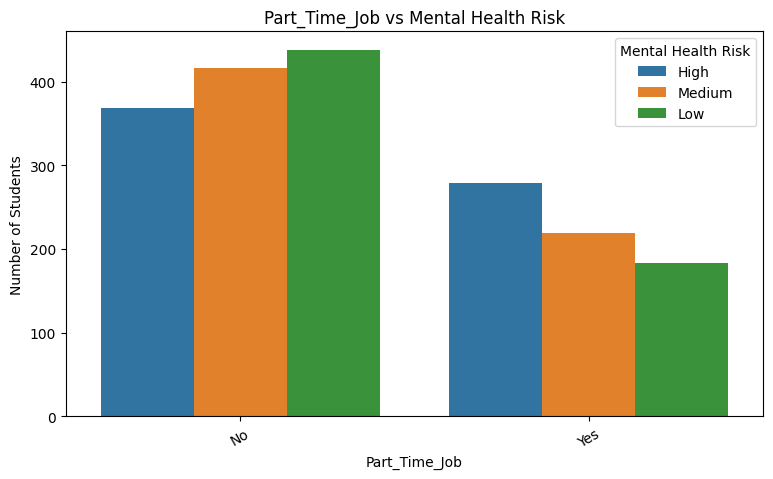

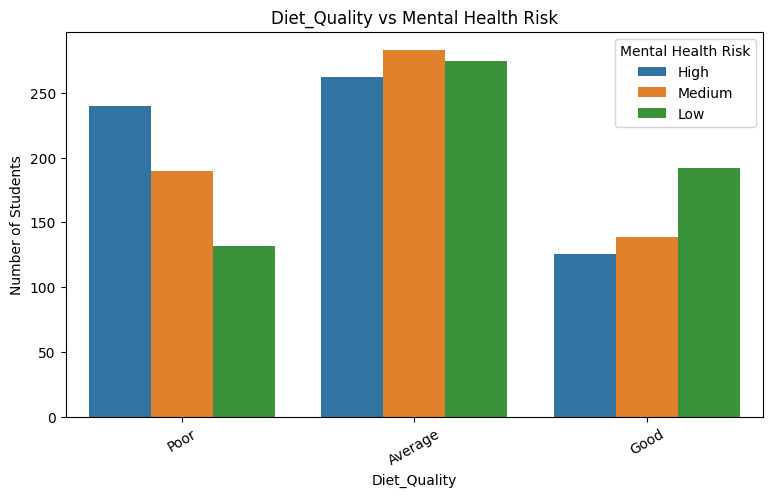

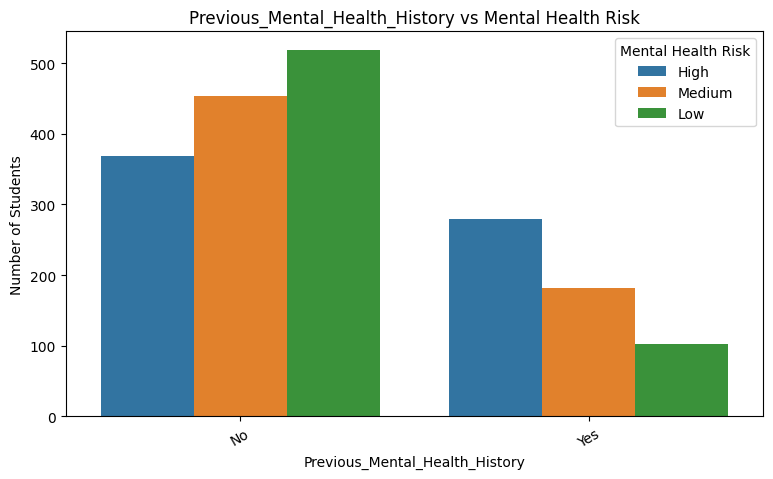

In [32]:

categorical_columns = df.select_dtypes(include="object").columns.drop(
    ["Student_ID", TARGET], errors="ignore"
)

for column in categorical_columns:
    plt.figure(figsize=(9, 5))

    sns.countplot(data=df, x=column, hue=TARGET)

    plt.title(f"{column} vs Mental Health Risk")
    plt.xlabel(column)
    plt.ylabel("Number of Students")
    plt.xticks(rotation=30)

    plt.legend(title="Mental Health Risk")
    plt.show()

## EDA Conclusions

The Exploratory Data Analysis (EDA) revealed the following findings:

1. **Dataset Overview:** The dataset contains 1,903 rows and 17 columns, including numerical and categorical features.

2. **Missing Values:** Missing values were identified in seven features and will require appropriate imputation strategies.

3. **Target Distribution:** The three classes (High, Medium, and Low) are relatively balanced, so oversimpling techniques are not currently necessary.

4. **Outliers:** Potential outliers were identified in several numerical features and will be investigated during data preparation.

5. **Correlations:** The strongest numerical correlation was found between Year of Study and Study Hours Per Week (0.70).

6. **Feature Relationships:** Sleep Hours, Financial Stress, Family Support, and Previous Mental Health History show associations with the target variable.

### Final Conclusion

The EDA helped us understand the dataset's structure, quality, distributions, and relationships. These findings will guide the data preparation and preprocessing stage before training the machine learning models.
